# KSA health insurers: medical-segment benchmark (walkthrough)

This notebook reads the finished data and shows, step by step, how the conclusions in `reports/REPORT.md` follow from it.
It does **not** re-run the PDF extraction (that needs the PDFs in `data/raw/` and takes minutes; see the README). It only reads
`data/clean/`, `reports/tables/` and `data/clean/insurers.duckdb`.

**Small sample:** 7 insurers, 8 to 10 quarterly points each (Tawuniya 7, with gaps). Treat every interval as indicative.
Wording is "associated with", never causal, and nothing here says anything about claim denials.

In [1]:
from pathlib import Path
import os
# run from the project root whether the notebook is opened from notebooks/ or the root
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
import pandas as pd, duckdb
from IPython.display import Image, display
pd.set_option("display.width", 200, "display.max_columns", 30, "display.float_format", "{:,.3f}".format)

panel = pd.read_csv("data/clean/panel_segment.csv")
med = panel[panel.segment == "medical"]
print(panel.shape, "| insurers:", panel.insurer.nunique(), "| periods:", panel.period.nunique())

(138, 23) | insurers: 7 | periods: 15


## 1. What is in the panel

One row per insurer x period x segment (`medical`, `total`). Amounts are SAR thousands. Columns are defined in
`data/clean/DATA_DICTIONARY.md`. Coverage is uneven, and that matters for every later step.

In [2]:
cov = (med.groupby("insurer")
          .agg(quarters=("freq", lambda s: int((s == "quarter").sum())),
               derived_q4=("is_derived", "sum"),
               first=("period", "min"), last=("period", "max"))
          .reset_index())
cov

,insurer,quarters,derived_q4,first,last
0,alrajhitakaful,8,2,2024FY,2025Q4
1,bupa,10,2,2023FY,2025Q2
2,gig,8,2,2024FY,2025Q4
3,malath,8,2,2024FY,2025Q4
4,medgulf,8,2,2024FY,2025Q4
5,tawuniya,7,0,2023Q3,2025Q3
6,walaa,8,2,2024FY,2025Q4


Q4 is never filed on its own; where both a full-year and a nine-month figure exist it is **derived** as FY minus 9M and flagged
(`is_derived`). Tawuniya has no full-year filings, so it has no Q4 and no run of more than 3 contiguous quarters.

## 2. Why the medical segment: whole-company ratios are not a health benchmark

Only Bupa is mono-line medical. Medical is a small or medium part of everyone else's book.

In [3]:
share = (med[med.freq == "quarter"].groupby("insurer").medical_share_of_revenue.agg(["min", "max"]).round(3))
share.sort_values("max")

,min,max
insurer,,
walaa,0.097,0.217
gig,0.171,0.308
alrajhitakaful,0.215,0.353
malath,0.353,0.567
tawuniya,0.696,0.753
medgulf,0.678,0.830
bupa,1.000,1.000


## 3. Medical vs whole-company loss ratio

Pooled (ratio of sums) over printed quarters 2024Q1 to 2025Q2, the window common to all seven insurers. Derived Q4 is excluded.
`loss_ratio` here is **insurance service expenses / insurance revenue**, gross of reinsurance (see section 7).

In [4]:
peer = pd.read_csv("reports/tables/peer_comparison.csv")
cols = ["insurer", "medical_share_of_revenue", "medical_loss_ratio_pooled", "medical_lr_ci_low", "medical_lr_ci_high",
        "medical_service_margin_pooled", "total_loss_ratio_pooled", "rank_medical_lr", "rank_total_lr"]
peer[cols]

,insurer,medical_share_of_revenue,medical_loss_ratio_pooled,medical_lr_ci_low,medical_lr_ci_high,medical_service_margin_pooled,total_loss_ratio_pooled,rank_medical_lr,rank_total_lr
0,Tawuniya,0.721,0.915,0.864,0.967,0.077,0.835,1,3
1,Bupa Arabia,1.000,0.924,0.905,0.944,0.072,0.924,2,6
2,Malath,0.485,0.970,0.857,1.093,0.027,0.984,3,7
3,Medgulf,0.797,0.985,0.943,1.029,0.006,0.900,4,5
4,GIG (Saudi),0.282,1.080,0.984,1.176,-0.074,0.809,5,2
5,Al Rajhi Takaful,0.272,1.128,1.006,1.251,-0.128,0.840,6,4
6,Walaa,0.176,1.194,1.047,1.356,-0.193,0.584,7,1


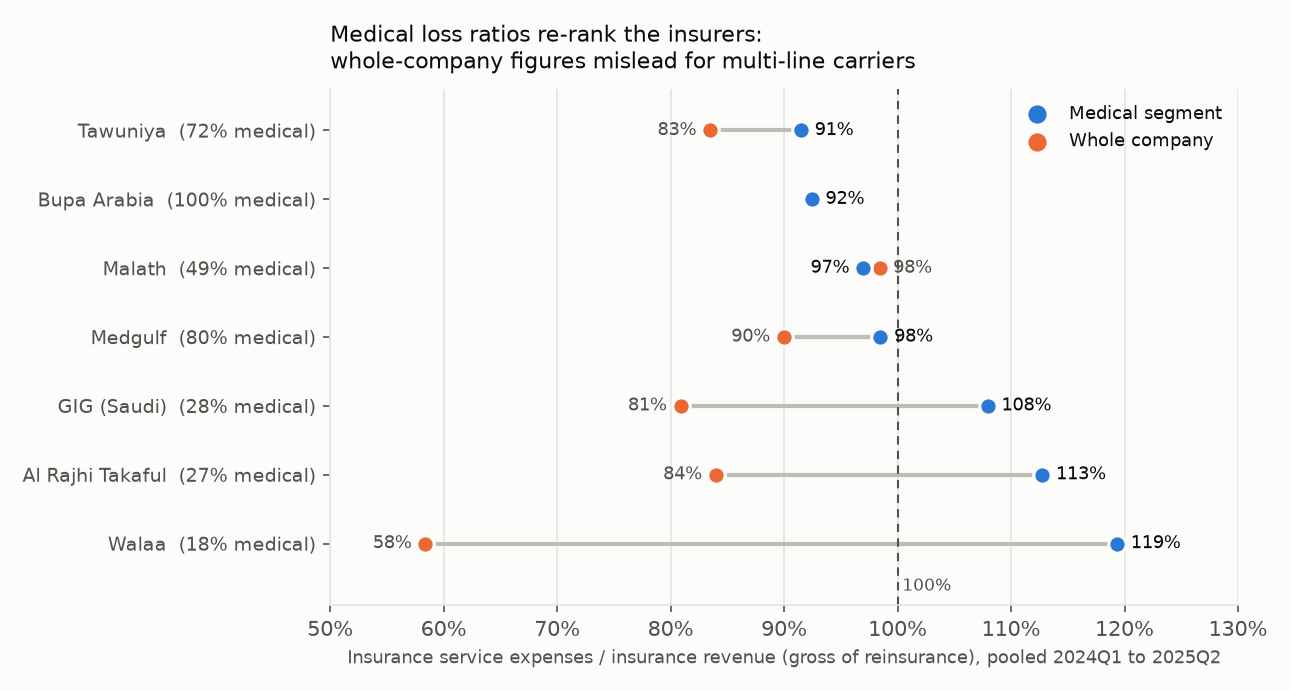

In [5]:
display(Image("reports/figures/fig1_medical_vs_total.png"))

The same insurers swap places between the two views: Walaa is best on whole-company figures and worst on medical; Bupa moves from
sixth to second. The rank correlation between the views is weak and not significant with n = 7:

In [6]:
from scipy.stats import spearmanr
r1 = spearmanr(peer.medical_loss_ratio_pooled, peer.total_loss_ratio_pooled)
r2 = spearmanr(peer.medical_share_of_revenue, peer.medical_loss_ratio_pooled)
print(f"medical vs whole-company loss ratio: rho = {r1.statistic:.2f}, p = {r1.pvalue:.3f}")
print(f"medical share vs medical loss ratio:  rho = {r2.statistic:.2f}, p = {r2.pvalue:.3f}  (association only; n = 7)")

medical vs whole-company loss ratio: rho = -0.54, p = 0.215
medical share vs medical loss ratio:  rho = -0.82, p = 0.023  (association only; n = 7)


## 4. Trend

A constant five-insurer group (Al Rajhi Takaful, GIG, Malath, Medgulf, Walaa) is used so composition does not change between
quarters. Hollow points in the figure are derived Q4 values; the statements below use printed quarters only.

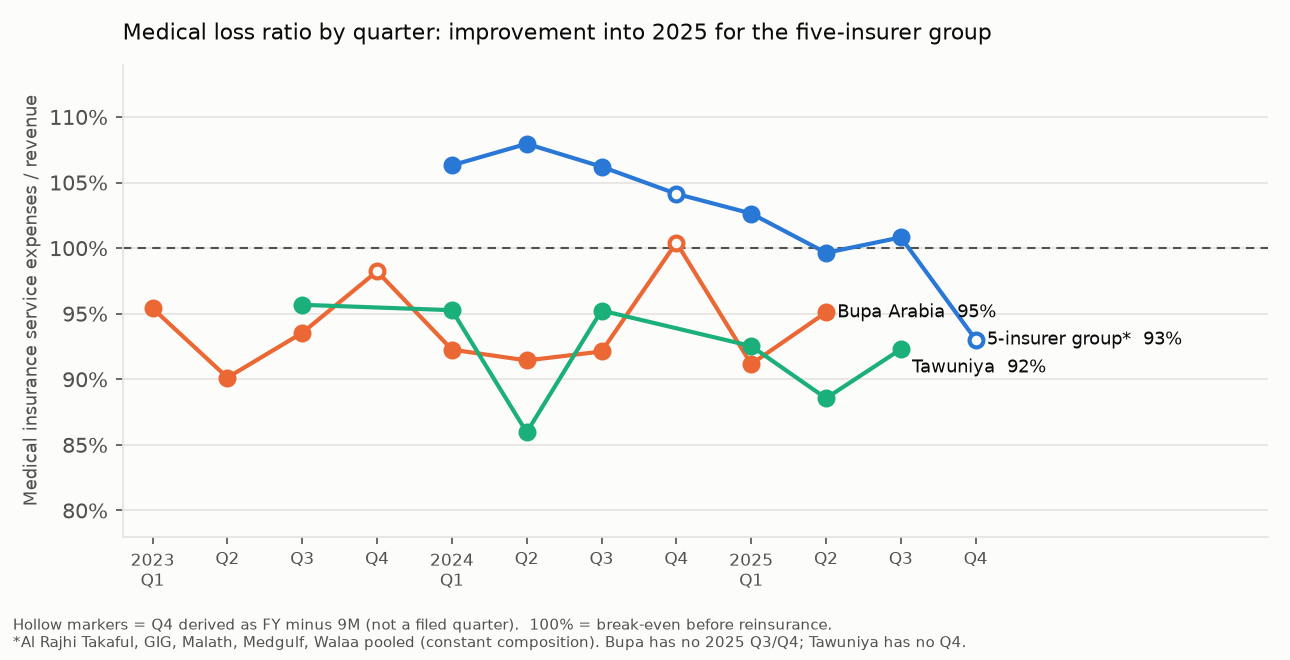

In [7]:
display(Image("reports/figures/fig2_quarterly_trend.png"))

In [8]:
q = med[(med.freq == "quarter") & (~med.is_derived)]
grp = ["alrajhitakaful", "gig", "malath", "medgulf", "walaa"]
def pooled(ins, periods):
    g = q[q.insurer.isin(ins) & q.period.isin(periods)]
    return g.claims.sum() / g.revenue.sum(), g.service_result.sum() / g.revenue.sum()
a = pooled(grp, ["2024Q1", "2024Q2", "2024Q3"]); b = pooled(grp, ["2025Q1", "2025Q2", "2025Q3"])
print(f"5-insurer pooled medical loss ratio, Q1-Q3: 2024 {a[0]:.1%} -> 2025 {b[0]:.1%}  ({100*(b[0]-a[0]):+.1f} pp)")
print(f"service margin:                              2024 {a[1]:.1%} -> 2025 {b[1]:.1%}")

5-insurer pooled medical loss ratio, Q1-Q3: 2024 106.8% -> 2025 101.0%  (-5.8 pp)
service margin:                              2024 -7.5% -> 2025 -1.1%


This group is only about 14% of Milliman's sector medical revenue in FY2025 (Bupa and Tawuniya are not in it), so it is **not** the
sector. For the sector, use Milliman's own table (p.15 of the PDF), loaded below.

In [9]:
from src.crosscheck import MILLIMAN_MEDICAL as M
M = M.assign(loss_ratio=M.claims / M.revenue, service_margin=M.service_result / M.revenue)
M[["period", "revenue", "loss_ratio", "service_margin"]].sort_values("period")

,period,revenue,loss_ratio,service_margin
3,2022FY,28328,0.966,0.027
2,2023FY,35620,0.952,0.046
1,2024FY,40357,0.962,0.034
0,2025FY,44648,0.956,0.040


## 5. Volatility and the forecast decision

In [10]:
vol = pd.read_csv("reports/tables/rolling_volatility.csv")
cov2 = pd.read_csv("reports/tables/coverage.csv")
display(vol.round(2))
display(cov2)
print("Forecast allowed (every insurer needs >= 8 contiguous quarterly points):", bool(cov2.meets_8_contiguous.all()))

,insurer,windows,latest_4q_std_pp,mean_4q_std_pp,max_4q_std_pp
0,Al Rajhi Takaful,5,14.910,8.800,14.910
1,Bupa Arabia,7,4.170,3.700,4.450
2,GIG (Saudi),5,7.810,7.580,8.860
3,Malath,5,4.620,6.570,8.880
4,Medgulf,5,1.760,2.860,3.870
5,Tawuniya,0,NaN,NaN,NaN
6,Walaa,5,13.910,17.860,21.360


,insurer,quarters,derived_q4,first,last,longest_contiguous_run,meets_8_contiguous
0,Al Rajhi Takaful,8,2,2024Q1,2025Q4,8,True
1,Bupa Arabia,10,2,2023Q1,2025Q2,10,True
2,GIG (Saudi),8,2,2024Q1,2025Q4,8,True
3,Malath,8,2,2024Q1,2025Q4,8,True
4,Medgulf,8,2,2024Q1,2025Q4,8,True
5,Tawuniya,7,0,2023Q3,2025Q3,3,False
6,Walaa,8,2,2024Q1,2025Q4,8,True


Forecast allowed (every insurer needs >= 8 contiguous quarterly points): False


Tawuniya has a longest contiguous run of 3, so the forecast is **not run**, by the project rule. Rolling four-quarter volatility
includes derived Q4 values where they exist.

## 6. SQL views (DuckDB)

The same panel is loaded into `data/clean/insurers.duckdb`; the views live in `sql/`. Example: peer rank for the latest quarter
that has the most insurers, then year-on-year change.

In [11]:
con = duckdb.connect("data/clean/insurers.duckdb", read_only=True)
display(con.execute('''
    SELECT insurer, period, round(loss_ratio, 3) AS loss_ratio, loss_ratio_rank, n_peers
    FROM v_medical_peer_rank WHERE period = '2025Q2' ORDER BY loss_ratio_rank
''').fetchdf())
display(con.execute('''
    SELECT insurer, period, round(loss_ratio, 3) AS loss_ratio,
           round(loss_ratio_yoy_pp, 1) AS yoy_pp, round(loss_ratio_qoq_pp, 1) AS qoq_pp
    FROM v_medical_changes WHERE freq = 'quarter' AND period IN ('2025Q2','2025Q3') ORDER BY period, insurer
''').fetchdf())

,insurer,period,loss_ratio,loss_ratio_rank,n_peers
0,malath,2025Q2,0.848,1,7
1,tawuniya,2025Q2,0.886,2,7
2,bupa,2025Q2,0.951,3,7
3,medgulf,2025Q2,0.961,4,7
4,alrajhitakaful,2025Q2,1.010,5,7
5,gig,2025Q2,1.077,6,7
6,walaa,2025Q2,1.385,7,7


,insurer,period,loss_ratio,yoy_pp,qoq_pp
0,alrajhitakaful,2025Q2,1.010,-23.400,-8.500
1,bupa,2025Q2,0.951,3.700,3.900
2,gig,2025Q2,1.077,-0.500,1.800
3,malath,2025Q2,0.848,-16.100,-5.400
4,medgulf,2025Q2,0.961,-1.800,-4.100
5,tawuniya,2025Q2,0.886,2.600,-4.000
6,walaa,2025Q2,1.385,13.700,27.700
7,alrajhitakaful,2025Q3,1.088,-13.000,7.800
8,gig,2025Q3,0.908,-29.100,-16.900
9,malath,2025Q3,0.952,-10.200,10.400


Missing prior periods give NULL, never a silently skipped gap (for example Tawuniya has no 2024Q4, so its 2025Q1 quarter-on-quarter
change is empty).

## 7. What the ratios do and do not measure

Under IFRS 17 the line *insurance service expenses* contains incurred claims **and** other directly attributable expenses such as
amortised acquisition costs. So the loss ratio here is an insurance-service-expense ratio, not a pure claims ratio. Bupa's roughly
2% "expense ratio" is only the separate *other operating expenses* line; its acquisition-cost amortisation (about 5% of revenue,
FY2024 note p.66) is inside the loss ratio. Expense and combined ratios exist at whole-company level only, because no insurer
allocates other operating expenses to segments. Details: `reports/RATIO_DEFINITIONS.md`.

In [12]:
t = panel[(panel.segment == "total") & (panel.freq == "annual")][["insurer", "period", "loss_ratio", "expense_ratio_total", "combined_ratio_total"]]
t.round(3)

,insurer,period,loss_ratio,expense_ratio_total,combined_ratio_total
10,alrajhitakaful,2024FY,0.865,0.023,0.888
15,alrajhitakaful,2025FY,0.849,0.030,0.879
32,bupa,2023FY,0.944,0.020,0.964
37,bupa,2024FY,0.941,0.019,0.960
54,gig,2024FY,0.841,0.033,0.874
59,gig,2025FY,0.922,0.031,0.953
74,malath,2024FY,0.966,0.031,0.996
79,malath,2025FY,1.022,0.024,1.046
94,medgulf,2024FY,0.893,NaN,NaN
99,medgulf,2025FY,0.933,NaN,NaN


## 8. How much to trust the data

Four independent checks, all reproducible from `tests/` and `reports/`:

In [13]:
audit = pd.read_csv("reports/audit_results.csv")
mil = pd.read_csv("reports/milliman_crosscheck.csv")
print(f"Random 10% audit (seed 42): {len(audit)} values checked against the PDFs, errors: {int((~audit.matches_pdf).sum())}")
print(audit.groupby(["method", "verified_by"]).size().to_string())
print()
print("Calculated vs printed service result, rows compared:", int(panel.printed_vs_calc_diff.notna().sum()),
      "| max difference:", panel.printed_vs_calc_diff.max())
tot = panel[(panel.segment == "total") & (~panel.is_derived)].merge(
    pd.read_csv("data/clean/panel.csv")[["insurer", "period", "revenue"]], on=["insurer", "period"], suffixes=("", "_stmt"))
print("Segment total vs consolidated statement revenue, periods compared:", len(tot),
      "| max difference:", (tot.revenue - tot.revenue_stmt).abs().max())
display(mil[["period", "n_insurers", "coverage_of_sector_revenue", "our_loss_ratio", "milliman_loss_ratio", "implied_rest_of_sector_loss_ratio"]])

Random 10% audit (seed 42): 52 values checked against the PDFs, errors: 0
method      verified_by                             
ocr         visual: matches rendered page               13
pdfplumber  text layer: printed number found on page    38
            visual: matches rendered page                1

Calculated vs printed service result, rows compared: 118 | max difference: 0.0
Segment total vs consolidated statement revenue, periods compared: 57 | max difference: 0.0


,period,n_insurers,coverage_of_sector_revenue,our_loss_ratio,milliman_loss_ratio,implied_rest_of_sector_loss_ratio
0,2025FY,5,0.138,0.990,0.956,0.950
1,2024FY,6,0.595,0.971,0.962,0.949
2,2023FY,1,0.446,0.944,0.952,0.958


**Reading the Milliman rows:** our insurers cover about 60% of Milliman's sector medical revenue in FY2024, so that comparison is
informative. FY2025 covers about 14% and is weak evidence. The segment total always equals the consolidated statement.

## 9. Limitations (repeat of the report)

* Seven insurers, at most 8 contiguous quarters; intervals use n = 5 quarters and ignore autocorrelation.
* Data start in 2023, so the IFRS 17 transition is not observed.
* Q4 is derived; Bupa has no 2025Q3/Q4 or FY2025; Tawuniya has no Q4.
* Ratios are gross of reinsurance, which flatters heavily reinsured books.
* Each insurer defines its own medical segment.